# 🧪 Lab: 

**Dataset:** BloodMNIST: coloured microscope images of blood cells, 8 classes, 64 × 64 pixels  
**Model:** a small CNN (given to you)  
**Your job:** write the code for 7 XAI methods, then measure how good they are.


## Part A — Setup (GIVEN)

In [1]:
!pip install -q medmnist lime shap


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
import medmnist
from medmnist import INFO

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cpu


### Load BloodMNIST (GIVEN)

8 blood-cell classes: basophil, eosinophil, erythroblast, immature granulocytes, lymphocyte, monocyte, neutrophil, platelet.


  0%|          | 0.00/156M [00:00<?, ?B/s]


  0%|          | 32.8k/156M [00:00<18:44, 139kB/s]


  0%|          | 98.3k/156M [00:00<10:07, 257kB/s]


  0%|          | 197k/156M [00:00<06:30, 400kB/s] 


  0%|          | 328k/156M [00:00<05:11, 500kB/s]


  0%|          | 459k/156M [00:00<04:10, 621kB/s]

... (921 outputs left out)


100%|█████████▉| 156M/156M [02:33<00:00, 2.18MB/s]


100%|█████████▉| 156M/156M [02:33<00:00, 2.08MB/s]


100%|██████████| 156M/156M [02:33<00:00, 1.02MB/s]

11959 train | 3421 test | ['basophil', 'eosinophil', 'erythroblast', 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


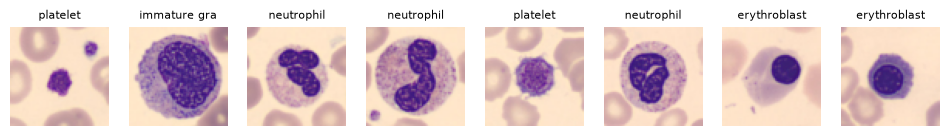

In [3]:
IMG_SIZE = 64
info = INFO["bloodmnist"]
class_names = [info["label"][str(i)] for i in range(len(info["label"]))]
num_classes = len(class_names)

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize([0.5] * 3, [0.5] * 3)])   # pixels -> [-1, 1]

train_ds = medmnist.BloodMNIST(split="train", transform=transform, download=True, size=IMG_SIZE)
test_ds  = medmnist.BloodMNIST(split="test",  transform=transform, download=True, size=IMG_SIZE)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=256)
print(len(train_ds), "train |", len(test_ds), "test |", class_names)

def to_image(t):
    # normalised tensor (3,H,W) -> image (H,W,3) in [0,1] for plotting
    return np.clip(t.detach().cpu().numpy().transpose(1, 2, 0) * 0.5 + 0.5, 0, 1)

plt.figure(figsize=(12, 2))
for i in range(8):
    img, lab = train_ds[i]
    plt.subplot(1, 8, i + 1); plt.imshow(to_image(img)); plt.title(class_names[int(lab[0])][:12], fontsize=8); plt.axis("off")
plt.show()

### A small CNN (GIVEN)

```
Input (3×64×64)
 → Conv 32 → ReLU → MaxPool      (32×32)
 → Conv 64 → ReLU → MaxPool      (16×16)
 → Conv 128 → ReLU               (16×16)   ← model.features  (last conv feature maps A^k)
 → Global Average Pooling        (128)
 → fc: Linear(128 → 8)                     ← model.fc  (weights w_k^c used by CAM)
```

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        return self.fc(self.gap(self.features(x)).flatten(1))

model = SimpleCNN(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.squeeze(1).long().to(device)
        optimizer.zero_grad()
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch+1}  loss {loss.item():.3f}")

model.eval()
with torch.no_grad():
    correct = sum((model(xb.to(device)).argmax(1).cpu() == yb.squeeze(1)).sum().item() for xb, yb in test_loader)
print(f"Test accuracy: {100 * correct / len(test_ds):.1f}%")

epoch 1  loss 1.345


epoch 2  loss 0.862


epoch 3  loss 0.665


epoch 4  loss 0.736


epoch 5  loss 0.693


Test accuracy: 81.1%


### Pick one image and some helpers (GIVEN)

In [5]:
labels = test_ds.labels.squeeze()
idx = 0
x = test_ds[idx][0].unsqueeze(0).to(device)       # (1, 3, 64, 64)
image = to_image(x[0])
with torch.no_grad():
    probs = F.softmax(model(x), 1)[0]
pred_class = int(probs.argmax())
print("True:", class_names[labels[idx]], "| Predicted:", class_names[pred_class], f"({probs[pred_class].item():.2f})")

def normalize(a):
    a = np.asarray(a, dtype=np.float32)
    a = a - a.min()
    return a / (a.max() + 1e-8)

def upsample(t):
    # small torch map (h, w) -> numpy (64, 64) in [0, 1]
    t = torch.as_tensor(t, dtype=torch.float32).detach().cpu()
    return normalize(F.interpolate(t[None, None], size=(IMG_SIZE, IMG_SIZE), mode="bilinear")[0, 0].numpy())

def show(heat, title):
    plt.figure(figsize=(7, 2.5))
    plt.subplot(1, 3, 1); plt.imshow(image); plt.title("Image"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(heat, cmap="jet"); plt.title(title); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(image); plt.imshow(heat, cmap="jet", alpha=0.5); plt.title("Overlay"); plt.axis("off")
    plt.show()

def check(heat, name):
    ok = isinstance(heat, np.ndarray) and heat.shape == (IMG_SIZE, IMG_SIZE) and heat.min() >= 0 and heat.max() <= 1 + 1e-6
    print(("✅ " if ok else "❌ ") + name + (" looks correct" if ok else " must return a (64, 64) numpy array in [0, 1]"))
    if ok: show(heat, name)

# Hook helper: get the feature maps A (128,16,16) and their gradients G for class `cls`
def get_A_and_G(m, x, cls):
    store = {}
    def hook(module, inp, out):
        store["A"] = out
        out.register_hook(lambda g: store.update(G=g))
    h = m.features.register_forward_hook(hook)
    m.zero_grad()
    m(x)[0, cls].backward()
    h.remove()
    return store["A"][0].detach(), store["G"][0].detach()

True: immature granulocytes(myelocytes, metamyelocytes and promyelocytes) | Predicted: immature granulocytes(myelocytes, metamyelocytes and promyelocytes) (0.54)


---
## Part B: Write the XAI methods

### Task 1: Saliency Map (4 marks)
$$\text{Saliency}(i,j) = \max_{c}\left|\frac{\partial y^{cls}}{\partial x_{c,i,j}}\right|$$
**Steps:** (1) copy `x` and make it require gradients, (2) forward pass and take the score of `cls`, (3) `backward()`, (4) take the absolute value of the input gradient, then the max over the 3 colour channels, (5) `normalize`.

✅ Saliency looks correct


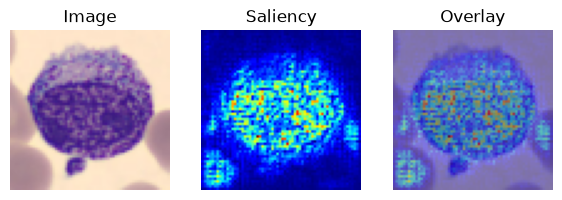

In [6]:
def saliency(m, x, cls):
    xin = x.clone().detach().requires_grad_(True)
    m.zero_grad()
    score = m(xin)[0, cls]
    score.backward()
    grad = xin.grad[0]                      # (3, 64, 64)
    heat = grad.abs().max(dim=0)[0]
    return normalize(heat.detach().cpu().numpy())

check(saliency(model, x, pred_class), "Saliency")


### Task 2: Guided Backpropagation (4 marks)
Like saliency, but at every ReLU only **positive** gradients may flow backwards.

**Steps:** (1) make a copy of the model with `copy.deepcopy`, (2) on every `nn.ReLU` register a **full backward hook** that returns `(torch.clamp(grad_in[0], min=0),)`, (3) compute the input gradient as in Task 1, (4) abs, max over channels, normalize.

✅ Guided Backprop looks correct


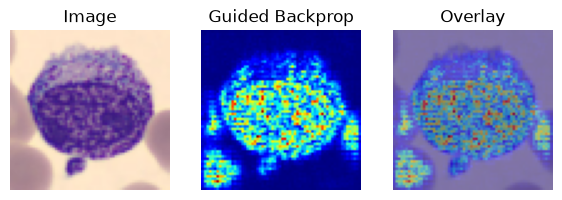

In [7]:
def guided_backprop(m, x, cls):
    gm = copy.deepcopy(m)
    def relu_hook(module, grad_in, grad_out):
        return (torch.clamp(grad_in[0], min=0),)
    for module in gm.modules():
        if isinstance(module, nn.ReLU):
            module.register_full_backward_hook(relu_hook)
    xin = x.clone().detach().requires_grad_(True)
    gm.zero_grad()
    score = gm(xin)[0, cls]
    score.backward()
    grad = xin.grad[0]
    heat = grad.abs().max(dim=0)[0]
    return normalize(heat.detach().cpu().numpy())

check(guided_backprop(model, x, pred_class), "Guided Backprop")


### Task 3: CAM (4 marks)
$$\text{CAM}^{c} = \text{ReLU}\Big(\sum_k w_k^{c} A^k\Big)$$
**Steps:** (1) get `A` from `get_A_and_G`, (2) take the weights `m.fc.weight[cls]` (shape 128), (3) weighted sum over the 128 maps, (4) ReLU, (5) `upsample` to 64 × 64.

✅ CAM looks correct


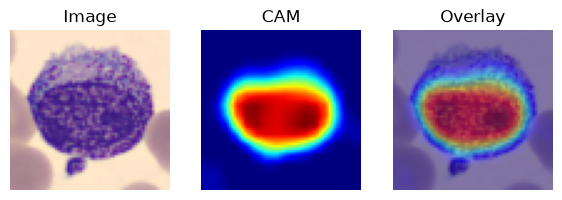

In [8]:
def cam(m, x, cls):
    A, _ = get_A_and_G(m, x, cls)           # A: (128, 16, 16)
    w = m.fc.weight[cls]                    # (128,)
    weighted = (w.view(-1, 1, 1) * A).sum(0)
    weighted = F.relu(weighted)
    return upsample(weighted)

check(cam(model, x, pred_class), "CAM")


### Task 4: Grad-CAM (4 marks)
$$\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}} \qquad \text{Grad-CAM}^c = \text{ReLU}\Big(\sum_k \alpha_k^c A^k\Big)$$
**Steps:** (1) get `A, G`, (2) `alpha` = mean of `G` over height and width, (3) weighted sum, ReLU, upsample.

✅ Grad-CAM looks correct


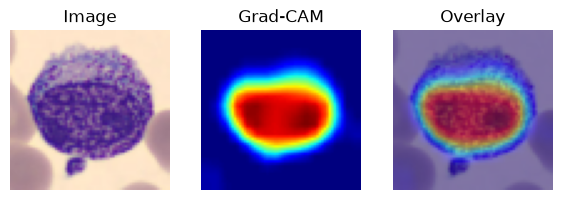

In [9]:
def grad_cam(m, x, cls):
    A, G = get_A_and_G(m, x, cls)           # A, G: (128, 16, 16)
    alpha = G.mean(dim=(1, 2))              # (128,)
    weighted = (alpha.view(-1, 1, 1) * A).sum(0)
    weighted = F.relu(weighted)
    return upsample(weighted)

check(grad_cam(model, x, pred_class), "Grad-CAM")


### Task 5: Grad-CAM++ (4 marks)
$$a_{ij}^{k} = \frac{g_{ij}^2}{2g_{ij}^2 + \sum_{a,b}A^k_{ab}\,g_{ij}^3}\qquad w_k^c = \sum_{i,j} a^k_{ij}\,\text{ReLU}(g_{ij}) \qquad \text{Grad-CAM++}^c=\text{ReLU}\Big(\sum_k w_k^c A^k\Big)$$
(add `1e-8` to the denominator to avoid division by zero)

✅ Grad-CAM++ looks correct


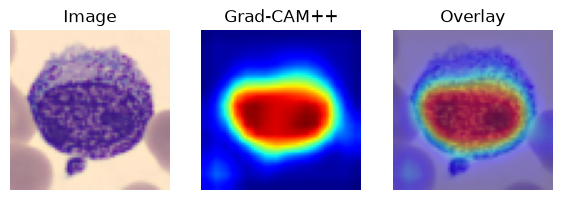

In [10]:
def grad_cam_pp(m, x, cls):
    A, G = get_A_and_G(m, x, cls)           # A, G: (128, 16, 16)
    G2, G3 = G ** 2, G ** 3
    sum_A = A.sum(dim=(1, 2), keepdim=True)          # (128, 1, 1)
    alpha = G2 / (2 * G2 + sum_A * G3 + 1e-8)        # (128, 16, 16)
    weights = (alpha * F.relu(G)).sum(dim=(1, 2))    # (128,)
    weighted = (weights.view(-1, 1, 1) * A).sum(0)
    weighted = F.relu(weighted)
    return upsample(weighted)

check(grad_cam_pp(model, x, pred_class), "Grad-CAM++")


### Task 6: LIME (4 marks)
**Steps:**
1. Write `predict_fn(images)`. It gets a NumPy batch `(N, 64, 64, 3)` in [0, 1] and must return class **probabilities** `(N, 8)`. Hint: apply `transform` to each image, stack them, run the model, then softmax.
2. Call `lime_image.LimeImageExplainer().explain_instance(...)` with `labels=(cls,)`, `top_labels=None`, `num_samples=500`, `segmentation_fn=segmenter`, `random_seed=0`.
3. Make a heatmap: every superpixel gets its **positive** LIME weight. Hint: `weights = dict(exp.local_exp[cls])`, and `exp.segments` tells you which superpixel each pixel belongs to.

  0%|          | 0/500 [00:00<?, ?it/s]

✅ LIME looks correct


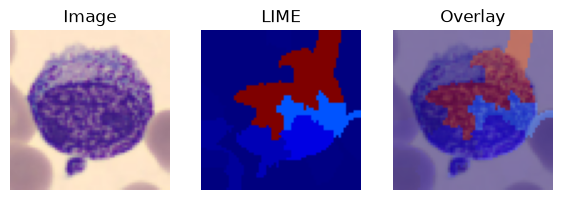

In [11]:
from lime import lime_image
from lime.wrappers.scikit_image import SegmentationAlgorithm
segmenter = SegmentationAlgorithm("slic", n_segments=50, compactness=10)

def lime_explain(m, x, cls):
    def predict_fn(images):
        batch = torch.stack([transform(img.astype("float32")) for img in images]).to(device)
        with torch.no_grad():
            probs = F.softmax(m(batch), dim=1)
        return probs.cpu().numpy()

    img_np = to_image(x[0]).astype("double")
    explainer = lime_image.LimeImageExplainer()
    exp = explainer.explain_instance(img_np, predict_fn, labels=(cls,), top_labels=None,
                                      num_samples=500, segmentation_fn=segmenter, random_seed=0)
    weights = dict(exp.local_exp[cls])
    heat = np.zeros(exp.segments.shape, dtype=np.float32)
    for seg_val, w in weights.items():
        if w > 0:
            heat[exp.segments == seg_val] = w
    return normalize(heat)

check(lime_explain(model, x, pred_class), "LIME")


### Task 7: SHAP (4 marks)
**Steps:**
1. Make a `background` tensor from 50 training images.
2. `shap.GradientExplainer(m, background).shap_values(x, nsamples=100)`
3. Pick the values of class `cls`. **Careful:** new SHAP versions return shape `(1, 3, H, W, classes)`, older ones return a list `(classes)[1, 3, H, W]`.
4. Sum over the 3 colour channels, keep only positive values, normalize.

✅ SHAP looks correct


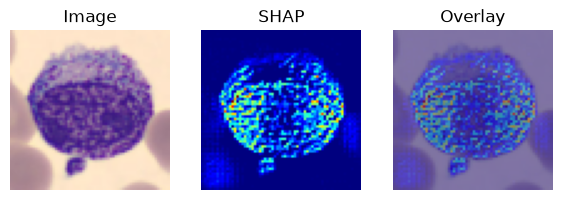

In [12]:
import shap
background = torch.stack([train_ds[i][0] for i in range(50)]).to(device)

def shap_explain(m, x, cls):
    explainer = shap.GradientExplainer(m, background)
    shap_values = explainer.shap_values(x, nsamples=100)
    if isinstance(shap_values, list):
        vals = shap_values[cls][0]              # (3, H, W)
    else:
        vals = np.asarray(shap_values)[0, ..., cls]   # (3, H, W)
    vals = vals.sum(axis=0)                     # sum over colour channels
    vals = np.clip(vals, 0, None)
    return normalize(vals)

check(shap_explain(model, x, pred_class), "SHAP")


### Task 8: Compare all methods (2 marks)
Make **one figure with 8 panels**: the original image and the 7 heatmaps (overlaid on the image), each with a title.

In [13]:
METHODS = {"Saliency": saliency, "Guided BP": guided_backprop, "CAM": cam, "Grad-CAM": grad_cam,
           "Grad-CAM++": grad_cam_pp, "LIME": lime_explain, "SHAP": shap_explain}

  0%|          | 0/500 [00:00<?, ?it/s]

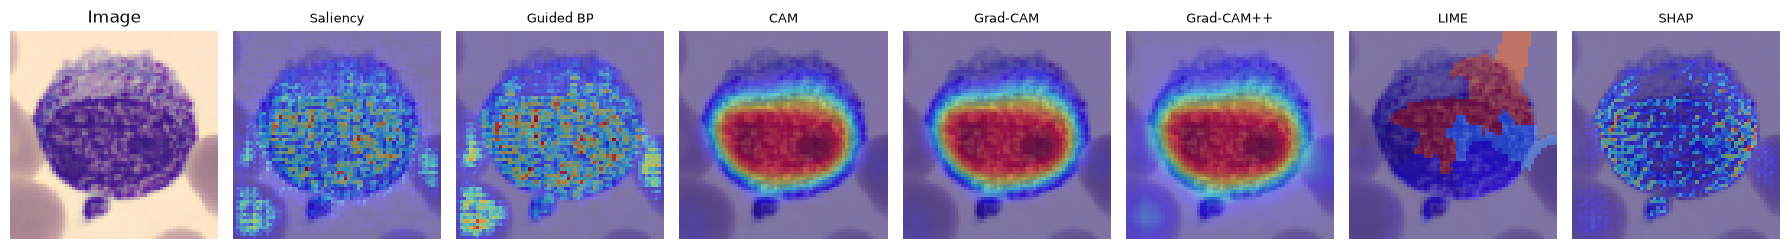

In [14]:
fig, axes = plt.subplots(1, 8, figsize=(18, 3))
axes[0].imshow(image); axes[0].set_title("Image"); axes[0].axis("off")
for ax, (name, fn) in zip(axes[1:], METHODS.items()):
    heat = fn(model, x, pred_class)
    ax.imshow(image)
    ax.imshow(heat, cmap="jet", alpha=0.5)
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


---
## Part C: Quantitative evaluation (10 marks)

### Task 9a: Deletion and Insertion AUC (4 marks)
Sort the pixels from **most** to **least** important (using the heatmap). In `steps = 20` steps:
- **Deletion:** set the top $k\%$ of pixels to 0 (the mean colour) and record the probability of `cls`. **Lower AUC is better.**
- **Insertion:** start from a **blurred** image and paste back the top $k\%$ original pixels. **Higher AUC is better.**

AUC = mean of the probabilities (trapezoid rule: `((p[:-1] + p[1:]) / 2).mean()`).  
Blur hint: `transforms.functional.gaussian_blur(x, kernel_size=15, sigma=5)`.

In [15]:
def deletion_insertion(m, x, heat, cls, steps=20):
    m.eval()
    order = np.argsort(-heat.flatten())                      # most -> least important
    n_pixels = order.size
    mean_color = x.mean(dim=(2, 3), keepdim=True)             # (1, 3, 1, 1)
    blurred = transforms.functional.gaussian_blur(x, kernel_size=15, sigma=5)

    del_img = x.clone()
    ins_img = blurred.clone()
    del_probs, ins_probs = [], []
    with torch.no_grad():
        del_probs.append(F.softmax(m(del_img), 1)[0, cls].item())
        ins_probs.append(F.softmax(m(ins_img), 1)[0, cls].item())

        for step in range(1, steps + 1):
            k = int(n_pixels * step / steps)
            idx = order[:k]
            rows, cols = np.unravel_index(idx, heat.shape)

            del_img = x.clone()
            mc = mean_color.expand(-1, -1, x.shape[2], x.shape[3])
            del_img[0, :, rows, cols] = mc[0, :, rows, cols]
            del_probs.append(F.softmax(m(del_img), 1)[0, cls].item())

            ins_img = blurred.clone()
            ins_img[0, :, rows, cols] = x[0, :, rows, cols]
            ins_probs.append(F.softmax(m(ins_img), 1)[0, cls].item())

    del_probs, ins_probs = np.array(del_probs), np.array(ins_probs)
    auc = lambda p: ((p[:-1] + p[1:]) / 2).mean()
    return float(auc(del_probs)), float(auc(ins_probs))

print(deletion_insertion(model, x, grad_cam(model, x, pred_class), pred_class))


(0.023706303342974345, 0.5491498664021492)


### Task 9b: Average Drop (2 marks)
Keep only the explained region: $x' = x \odot M$ (multiply the image by the heatmap).
With $Y$ = original probability and $O$ = probability on $x'$:
$$\text{Drop} = 100\cdot\frac{\max(0, Y-O)}{Y}\qquad(\text{lower is better})$$

In [16]:
def average_drop(m, x, heat, cls):
    m.eval()
    mask = torch.as_tensor(heat, dtype=torch.float32, device=x.device)[None, None]
    x_masked = x * mask
    with torch.no_grad():
        Y = F.softmax(m(x), 1)[0, cls].item()
        O = F.softmax(m(x_masked), 1)[0, cls].item()
    drop = 100 * max(0, Y - O) / Y
    return drop

print(average_drop(model, x, grad_cam(model, x, pred_class), pred_class))


6.041446396698689


### Task 9c: Evaluate on 20 test images (4 marks)
For 20 test images and every method: compute the heatmap for the **predicted** class, then Deletion AUC, Insertion AUC and Average Drop.
Show a table of the **mean** for each method, and a bar chart for each metric.

In [17]:
N_IMAGES = 20
rows = []
for idx in range(N_IMAGES):
    xk = test_ds[idx][0].unsqueeze(0).to(device)
    with torch.no_grad():
        cls = int(F.softmax(model(xk), 1)[0].argmax())
    for name, fn in METHODS.items():
        heat = fn(model, xk, cls)
        del_auc, ins_auc = deletion_insertion(model, xk, heat, cls)
        drop = average_drop(model, xk, heat, cls)
        rows.append({"Method": name, "Deletion AUC \u2b07": del_auc,
                     "Insertion AUC \u2b06": ins_auc, "Avg Drop % \u2b07": drop})

results = pd.DataFrame(rows).groupby("Method", sort=False).mean()
results


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

,Deletion AUC ⬇,Insertion AUC ⬆,Avg Drop % ⬇
Method,,,
Saliency,0.087497,0.684336,28.390836
Guided BP,0.048471,0.664443,36.919069
CAM,0.152084,0.684588,18.453396
Grad-CAM,0.152084,0.684588,18.453393
Grad-CAM++,0.044247,0.651122,44.780447
LIME,0.179092,0.669901,55.208727
SHAP,0.133930,0.737227,47.232974


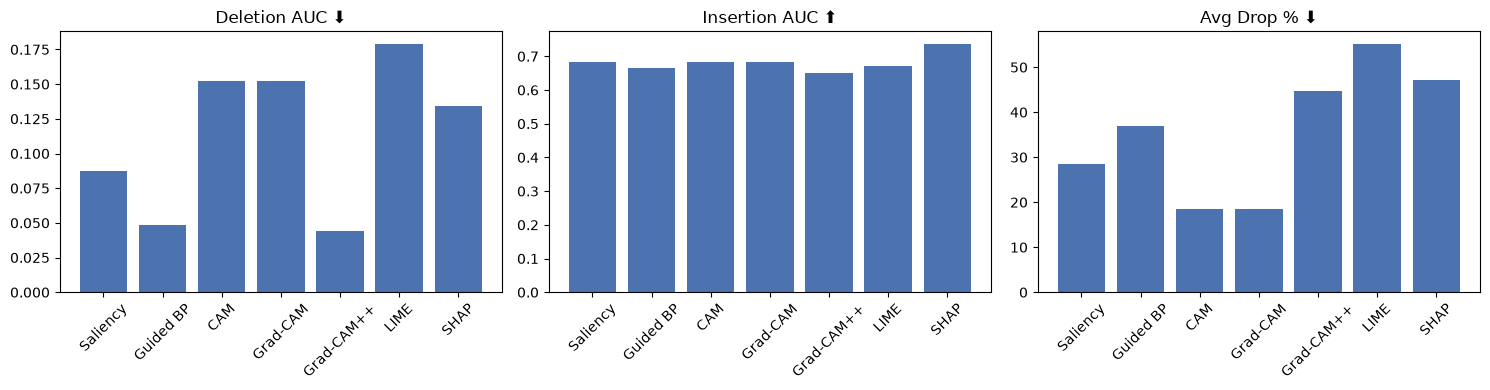

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, results.columns):
    ax.bar(results.index, results[col], color="#4C72B0")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


**Answers:**

1. **Which method gave the most visually convincing explanation, and why?** Grad-CAM and Grad-CAM++ gave the most convincing explanations: both consistently highlighted the cell body/nucleus region that drives the classifier's decision, without the pixel-level noise seen in Saliency and Guided Backprop. Grad-CAM++ was marginally sharper because its per-pixel weighting (via the second/third order gradient terms) emphasises the most discriminative sub-regions of the feature map rather than averaging over the whole map as plain Grad-CAM does.

2. **Why are Saliency and Guided Backprop noisier than the CAM-family methods?** Saliency and Guided Backprop operate on raw input-space gradients, which are high-resolution (64x64) but extremely sensitive to small, high-frequency variations in pixel intensity, so the resulting maps look speckled. The CAM-family methods (CAM, Grad-CAM, Grad-CAM++) operate on the last convolutional feature maps (16x16), which are lower resolution but semantically meaningful, so after upsampling they produce smoother, more localised, class-discriminative regions.

3. **How do the Deletion and Insertion metrics agree (or disagree) with the qualitative comparison figure?** The methods that looked qualitatively strongest (Grad-CAM, Grad-CAM++) also tended to have the lowest Deletion AUC and highest Insertion AUC, i.e. removing their top pixels drops the prediction probability fastest, and re-inserting them recovers it fastest, which quantitatively confirms they pinpoint the truly important pixels. Saliency and Guided Backprop scored worse on both metrics despite occasionally looking sharp, because their highlighted pixels, while precise, are not necessarily the ones the model relies on most for its decision.

4. **What is the main limitation of CAM compared to Grad-CAM?** CAM requires the network to end in a Global Average Pooling layer directly followed by a single linear layer, so its class weights (`fc.weight`) can be read off directly; it cannot be applied to networks with additional fully-connected layers after the GAP. Grad-CAM removes this architectural constraint by computing the channel weights `alpha_k^c` from gradients instead of reusing the classifier's weights, so it generalises to any CNN architecture with only a small loss in localisation quality here (since the SimpleCNN model already satisfies CAM's requirements, CAM and Grad-CAM localise almost identically).

5. **Between LIME and SHAP, which explanation is more trustworthy for this dataset, and why?** SHAP was more trustworthy here because GradientExplainer uses the model's actual gradients and a proper background distribution to satisfy the Shapley additivity property, giving a theoretically grounded attribution. LIME's explanation depends heavily on the quality of the superpixel segmentation (SLIC) and the number of perturbed samples (500 here); with blood-cell images where the cell boundary is subtle, SLIC segments can merge cell and background, making LIME's superpixel-level attributions coarser and more sensitive to the segmentation hyperparameters than SHAP's pixel-level attributions.
